# 03 – Análise descritiva

**Objetivo:** descrever o dataset limpo e explorar, de forma descritiva, as hipóteses do projeto:
estatísticas resumo, comparações entre grupos, visualizações e matriz de correlação.

**Escopo:** Não serão aplicados testes de hipótese. As hipóteses são
tratadas como exploratórias, e as conclusões descrevem este conjunto de dados, sem generalização.

In [13]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.funcoes import (
    carregar_dados, contar_artistas, 
    configurar_estilo, plotar_barras_horizontais,
    plotar_histograma, analisar_descritiva,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
df = carregar_dados("../data/spotify_2023_limpo.csv")

df["data_lancamento"] = pd.to_datetime(df["data_lancamento"])
df = df.set_index("id_original")

df.info()

configurar_estilo()

Dados carregados: 949 linhas e 22 colunas.
<class 'pandas.DataFrame'>
Index: 949 entries, 0 to 952
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   track_name            949 non-null    str           
 1   artist_name           949 non-null    str           
 2   artist_count          949 non-null    int64         
 3   released_year         949 non-null    int64         
 4   released_month        949 non-null    int64         
 5   released_day          949 non-null    int64         
 6   streams               947 non-null    float64       
 7   in_spotify_playlists  949 non-null    int64         
 8   in_spotify_charts     949 non-null    int64         
 9   bpm                   949 non-null    int64         
 10  key                   949 non-null    str           
 11  mode                  949 non-null    str           
 12  danceability          949 non-null    int64        

## 1. Descrição do dataset

### 1.1 Artistas mais frequentes
Músicas com colaboração têm vários artistas na mesma célula (`"A, B"`). Para contar cada artista,
separa-se os nomes. Antes, valida-se a separação: o número de nomes obtido deve coincidir com
a coluna `artist_count`.

In [3]:
n_nomes = df["artist_name"].str.split(", ").str.len()
divergentes = df[n_nomes != df["artist_count"]]

print(f"Músicas em que o número de nomes difere de artist_count: {len(divergentes)}")
divergentes[["track_name", "artist_name", "artist_count"]].assign(nomes_separados=n_nomes)

Músicas em que o número de nomes difere de artist_count: 1


,track_name,artist_name,artist_count,nomes_separados
id_original,,,,
667,"Cay�� La Noche (feat. Cruz Cafun��, Abhir Hath...","Quevedo, La Pantera, Juseph, Cruz Cafun��, B��...",7,6


In [4]:
contagem_artistas = contar_artistas(df, "artist_name")

print(f"Artistas distintos: {len(contagem_artistas)}")
contagem_artistas.head(15)

Artistas distintos: 698


artist_name
Bad Bunny         40
Taylor Swift      38
The Weeknd        36
SZA               23
Kendrick Lamar    23
Feid              21
Drake             19
Harry Styles      17
Peso Pluma        16
21 Savage         14
Metro Boomin      14
Ed Sheeran        14
Morgan Wallen     13
BTS               13
Quevedo           12
Name: count, dtype: int64

In [5]:
top_artistas = contagem_artistas.head(15).index
todos_os_nomes = contagem_artistas.index

for artista in top_artistas:
    variantes = [nome for nome in todos_os_nomes
                 if nome != artista and artista.startswith(nome)]
    if variantes:
        contagens = {nome: contagem_artistas[nome] for nome in variantes}
        print(f"{artista}: {contagens}")

Bad Bunny: {'Bad B': np.int64(1)}
Peso Pluma: {'Peso P': np.int64(2)}
Metro Boomin: {'M': np.int64(1)}
Morgan Wallen: {'M': np.int64(1)}


In [6]:
tem_nome_vazio = df["artist_name"].str.split(", ").apply(
    lambda nomes: any(nome.strip() == "" for nome in nomes)
)
df.loc[tem_nome_vazio, ["track_name", "artist_name", "artist_count"]]

,track_name,artist_name,artist_count
id_original,,,
742,Vampiro,"Matu��, Wiu,",3


In [7]:
tem_m = df["artist_name"].str.split(", ").apply(lambda nomes: "M" in nomes)
df.loc[tem_m, ["track_name", "artist_name", "released_year"]]

,track_name,artist_name,released_year
id_original,,,
488,Tubar��o Te,"Dj LK da Esc��cia, Tchakabum, mc jhenny, M",2022


**Nomes truncados:** buscando nomes que são o início de artistas do top 15, encontra-se
"Bad B" (Bad Bunny, 1 ocorrência) e "Peso P" (Peso Pluma, 2), que são corrigidos antes da contagem.
"M" não é corrigido, pois não da para saber de qual artista se trata.
Duas músicas perderam um artista inteiro no truncamento ("Cayó La Noche" e
"Vampiro"); o nome vazio gerado em "Vampiro" é descartado. Limitação: pequena subcontagem.

In [8]:
correcoes_artistas = {
    "Bad B": "Bad Bunny",
    "Peso P": "Peso Pluma",
}

contagem_artistas = contar_artistas(df, "artist_name", correcoes=correcoes_artistas)

print(f"Artistas distintos: {len(contagem_artistas)}")
assert contagem_artistas["Bad Bunny"] == 41, "Bad Bunny deveria ter 41"
assert contagem_artistas["Peso Pluma"] == 18, "Peso Pluma deveria ter 18"
assert "" not in contagem_artistas.index, "Não deveria haver nome vazio"

contagem_artistas.head(15)

Artistas distintos: 696


artist_name
Bad Bunny         41
Taylor Swift      38
The Weeknd        36
SZA               23
Kendrick Lamar    23
Feid              21
Drake             19
Peso Pluma        18
Harry Styles      17
21 Savage         14
Metro Boomin      14
Ed Sheeran        14
Morgan Wallen     13
BTS               13
Quevedo           12
Name: count, dtype: int64

In [9]:
# Testando se a função 'contar_artistas' está funcionando corretamente:

teste = pd.DataFrame({"art": ["A, B", "A", "B, Bx, ", "C"]})
resultado = contar_artistas(teste, "art", correcoes={"Bx": "B"})
print(resultado)

assert resultado["A"] == 2, "A aparece 2 vezes"
assert resultado["B"] == 3, "B aparece 1 vez + 'Bx' corrigido + 1 na linha 3"
assert "" not in resultado.index, "O nome vazio deveria ser descartado"
assert len(resultado) == 3, "Deveriam sobrar só A, B e C"
print("Testes OK")

art
B    3
A    2
C    1
Name: count, dtype: int64
Testes OK


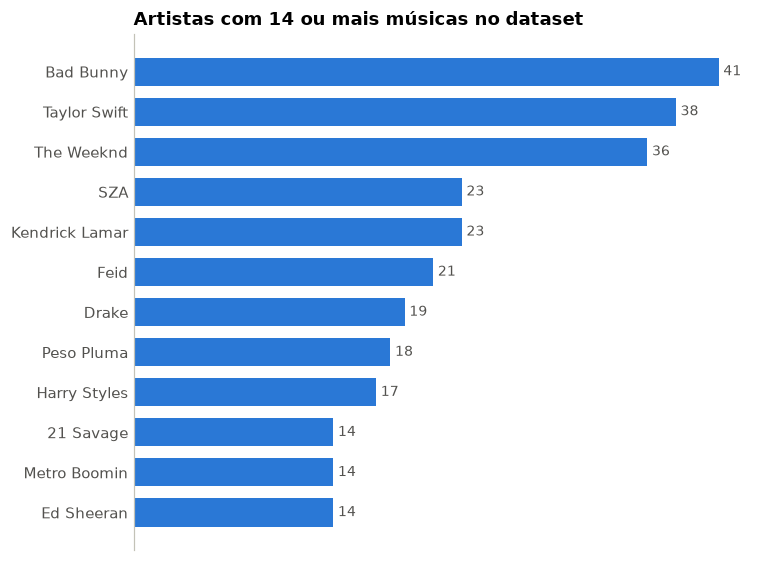

In [10]:
top_artistas = contagem_artistas[contagem_artistas >= 14]

fig, ax = plotar_barras_horizontais(
    top_artistas,
    titulo="Artistas com 14 ou mais músicas no dataset",
    caminho="../figures/artistas_mais_frequentes.png",
)

**Leitura:** o dataset é concentrado em poucos artistas. Bad Bunny (41), Taylor Swift (38) e
The Weeknd (36) somam 115 músicas, cerca de 12% do total. Isso reflete o efeito de lançamentos de
álbuns de sucesso, que colocam várias faixas entre as mais ouvidas ao mesmo tempo.

### 1.2 Distribuição dos anos de lançamento
O dataset reúne as músicas mais ouvidas em 2023, mas inclui lançamentos de várias épocas.
Vemos primeiro a distribuição por década (panorama) e depois ano a ano a partir de 2010 (detalhe).

[Text(0, 0, '2'),
 Text(0, 0, '9'),
 Text(0, 0, '4'),
 Text(0, 0, '7'),
 Text(0, 0, '12'),
 Text(0, 0, '14'),
 Text(0, 0, '20'),
 Text(0, 0, '151'),
 Text(0, 0, '730')]

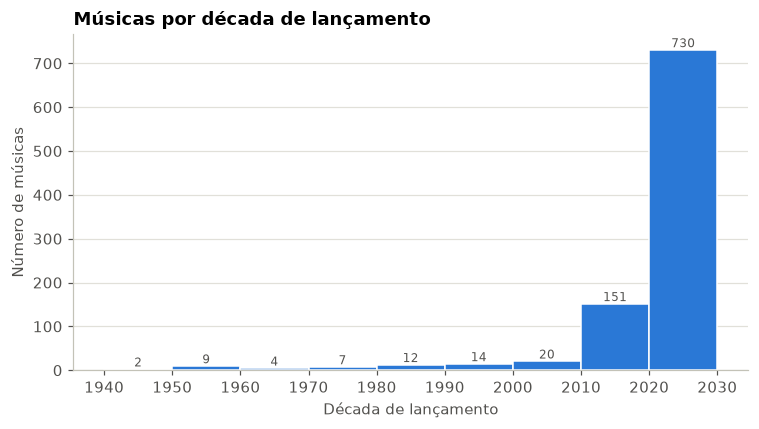

In [11]:
decadas = list(range(1940, 2031, 10))

fig, ax = plotar_histograma(
    df["released_year"],
    bins=decadas,
    titulo="Músicas por década de lançamento",
    rotulo_x="Década de lançamento",
    caminho="../figures/anos_por_decada.png",
)
ax.set_xticks(decadas)
ax.bar_label(ax.containers[0], fontsize=8, color="#52514e")

[Text(0, 0, '7'),
 Text(0, 0, '10'),
 Text(0, 0, '10'),
 Text(0, 0, '13'),
 Text(0, 0, '13'),
 Text(0, 0, '11'),
 Text(0, 0, '18'),
 Text(0, 0, '23'),
 Text(0, 0, '10'),
 Text(0, 0, '36'),
 Text(0, 0, '37'),
 Text(0, 0, '118'),
 Text(0, 0, '400'),
 Text(0, 0, '175')]

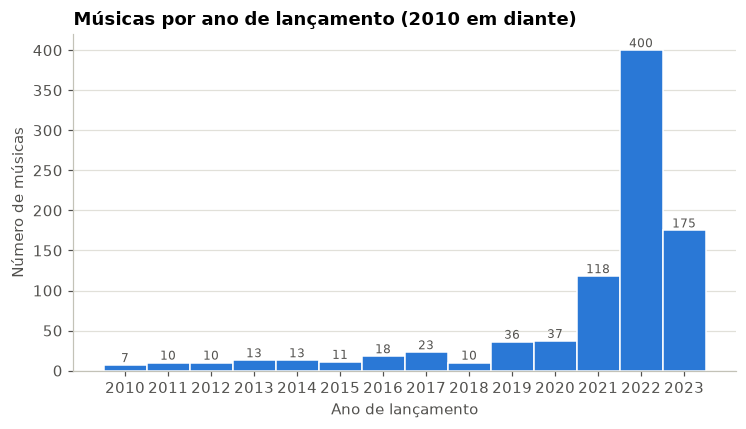

In [12]:
limites_recentes = np.arange(2009.5, 2024.5, 1)
anos_recentes = list(range(2010, 2024))

fig, ax = plotar_histograma(
    df.loc[df["released_year"] >= 2010, "released_year"],
    bins=limites_recentes,
    titulo="Músicas por ano de lançamento (2010 em diante)",
    rotulo_x="Ano de lançamento",
    caminho="../figures/anos_desde_2010.png",
)
ax.set_xticks(anos_recentes)
ax.bar_label(ax.containers[0], fontsize=8, color="#52514e")

**Leitura:** a distribuição dos anos é fortemente assimétrica à esquerda. A década de 2020 concentra
730 músicas (77%), mesmo cobrindo apenas 2020–2023; apenas 68 (7%) são anteriores a 2010
(clássicos, muitos natalinos). Entre as recentes, 2022 é o ano com mais músicas (400). 2023 tem
bem menos (175), apesar de o dataset ser das mais ouvidas em 2023: o ano estava incompleto na
coleta, e músicas recentes tiveram pouco tempo para acumular streams (viés de tempo de exposição).
Obs.: o gráfico conta músicas por período, não streams por música.

## 2. Distribuição das variáveis de sucesso
As três medidas de sucesso: `streams`, `in_spotify_playlists` e `in_spotify_charts`.

In [14]:
variaveis_sucesso = ["streams", "in_spotify_playlists", "in_spotify_charts"]
analisar_descritiva(df, variaveis_sucesso)

,n,média,mediana,desvio padrão,mínimo,Q1,Q3,máximo,assimetria
streams,947,"514,879,661.09","290,228,626.00","567,850,736.57","1,365,184.00","141,908,137.00","673,228,688.00","3,703,895,074.00",2.00
in_spotify_playlists,949,"5,214.33","2,224.00","7,911.05",31.00,875.00,"5,669.00","52,898.00",2.92
in_spotify_charts,949,12.06,3.00,19.60,0.00,0.00,16.00,147.00,2.57


### 2.1 Streams

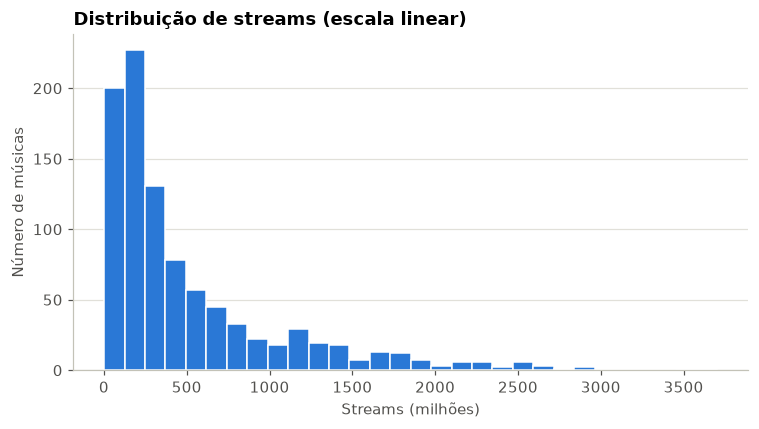

In [15]:
streams_mi = df["streams"] / 1_000_000

fig, ax = plotar_histograma(
    streams_mi,
    bins=30,
    titulo="Distribuição de streams (escala linear)",
    rotulo_x="Streams (milhões)",
)

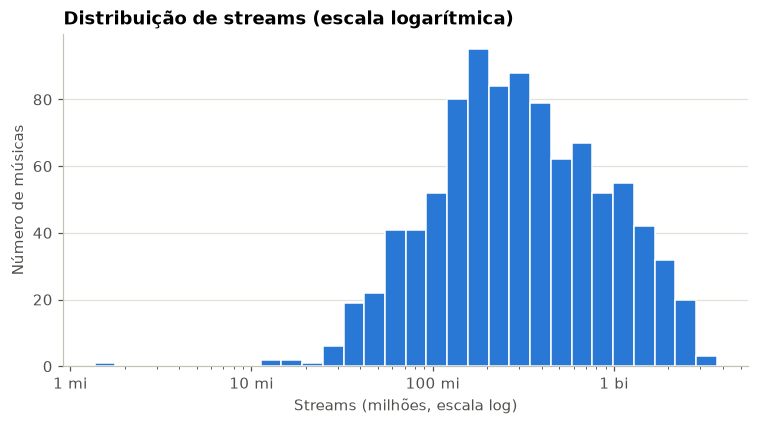

In [17]:
fig, ax = plotar_histograma(
    streams_mi,
    bins=30,
    titulo="Distribuição de streams (escala logarítmica)",
    rotulo_x="Streams (milhões, escala log)",
    escala_log=True,
    caminho="../figures/streams_histograma_log.png",
)

marcas = [1, 10, 100, 1000]
ax.set_xticks(marcas)
ax.set_xticklabels(["1 mi", "10 mi", "100 mi", "1 bi"])
fig.savefig("../figures/streams_histograma_log.png", bbox_inches="tight")

**Leitura:** as três medidas de sucesso têm assimetria forte à direita (coeficiente entre 2,0 e 2,9):
a média é bem maior que a mediana e, em `streams` e playlists, o desvio padrão supera a média.
Por isso, usa-se a **mediana** e os **quartis** como medidas de centro e dispersão.
Metade das músicas tem entre 142 mi (Q1) e 673 mi (Q3) de streams, com mediana de 290 mi.
Em escala linear, os valores baixos se concentram nas primeiras classes; em escala logarítmica,
a distribuição de `streams` fica aproximadamente simétrica, com pico
entre 150 e 400 milhões. Destacam-se um valor isolado em torno de 1 mi e um pequeno grupo entre
10 e 30 mi (lançamentos recentes, com pouco tempo de exposição).